# Loan Eligibility using Logistic Regression
**Task:** find whether a person is eligible for a loan.
**Graph required:** x-axis = CIBIL (credit) score, y-axis = loan amount required.

> The instructor wrote "Logical Regression". The technique is called **Logistic Regression**. It is used when the answer is Yes / No (eligible or not eligible).

> **Data note:** `loan_data.csv` is a synthetic (made-up) practice dataset of 500 applicants. To use a real dataset, replace the file and change the column names in Step 1.

## Step 1: Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv("../data/loan_data.csv")
print(df.shape)
print(df.head())
print(df.columns.tolist())

(500, 4)
   applicant_id  cibil_score  loan_amount  eligible
0             1          736      1890000         0
1             2          622       810000         0
2             3          774      3020000         0
3             4          790       640000         1
4             5          544      1850000         0
['applicant_id', 'cibil_score', 'loan_amount', 'eligible']


Columns:
- `cibil_score`: credit score (300 to 900, higher is better)
- `loan_amount`: amount the person wants to borrow (rupees)
- `eligible`: 1 = eligible, 0 = not eligible (this is what we want to predict)

## Step 2: Look at the data

In [2]:
df.info()
print("Missing values:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   applicant_id  500 non-null    int64
 1   cibil_score   500 non-null    int64
 2   loan_amount   500 non-null    int64
 3   eligible      500 non-null    int64
dtypes: int64(4)
memory usage: 15.8 KB
Missing values:
applicant_id    0
cibil_score     0
loan_amount     0
eligible        0
dtype: int64
Duplicate rows: 0


In [3]:
print(df[["cibil_score", "loan_amount"]].describe())
print(df["eligible"].value_counts())

       cibil_score   loan_amount
count   500.000000  5.000000e+02
mean    708.572000  2.510520e+06
std      80.644304  1.461979e+06
min     492.000000  5.000000e+04
25%     653.000000  1.250000e+06
50%     710.500000  2.470000e+06
75%     760.000000  3.802500e+06
max     900.000000  4.990000e+06
eligible
0    302
1    198
Name: count, dtype: int64


The data has no missing values or duplicates. About 40% of people are eligible, so both groups have enough rows.

## Step 3: Graph of the data (x = CIBIL score, y = loan amount)

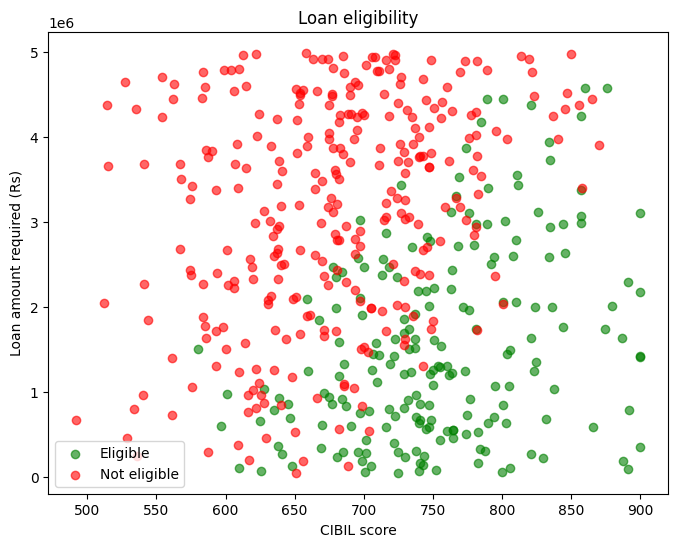

In [4]:
plt.figure(figsize=(8, 6))
yes = df[df["eligible"] == 1]
no = df[df["eligible"] == 0]
plt.scatter(yes["cibil_score"], yes["loan_amount"], color="green", label="Eligible", alpha=0.6)
plt.scatter(no["cibil_score"], no["loan_amount"], color="red", label="Not eligible", alpha=0.6)
plt.xlabel("CIBIL score")
plt.ylabel("Loan amount required (Rs)")
plt.title("Loan eligibility")
plt.legend()
plt.show()

**What we see:** green points (eligible) are mostly on the right (high CIBIL score) and low (small loan amount). Red points (not eligible) are mostly on the left or at the top. Logistic regression will draw the line that separates them.

## Step 4: Split into train and test

In [5]:
X = df[["cibil_score", "loan_amount"]]     # input: x-axis and y-axis of the graph
y = df["eligible"]                          # output: eligible or not

# 80% to train the model, 20% to test it
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("train rows:", len(X_train), " test rows:", len(X_test))

train rows: 400  test rows: 100


In [6]:
# CIBIL score is about 700 but loan amount is in lakhs of rupees (millions), so bring both to the same scale
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # learn the scale from train data only
X_test_s = scaler.transform(X_test)

## Step 5: Train the model

In [7]:
model = LogisticRegression()
model.fit(X_train_s, y_train)
print("coefficients (cibil, loan_amount):", model.coef_)
print("intercept:", model.intercept_)

coefficients (cibil, loan_amount): [[ 1.94066622 -2.11603086]]
intercept: [-0.92509317]


A **positive** coefficient for CIBIL score means a higher score increases the chance of approval. A **negative** coefficient for loan amount means asking for more money lowers the chance.

## Step 6: Predict and check accuracy

In [8]:
y_pred = model.predict(X_test_s)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.84
Confusion matrix:
[[53  7]
 [ 9 31]]
              precision    recall  f1-score   support

           0       0.85      0.88      0.87        60
           1       0.82      0.78      0.79        40

    accuracy                           0.84       100
   macro avg       0.84      0.83      0.83       100
weighted avg       0.84      0.84      0.84       100



The confusion matrix shows correct predictions on the diagonal and wrong predictions in the other two boxes.

## Step 7: Graph with the decision line

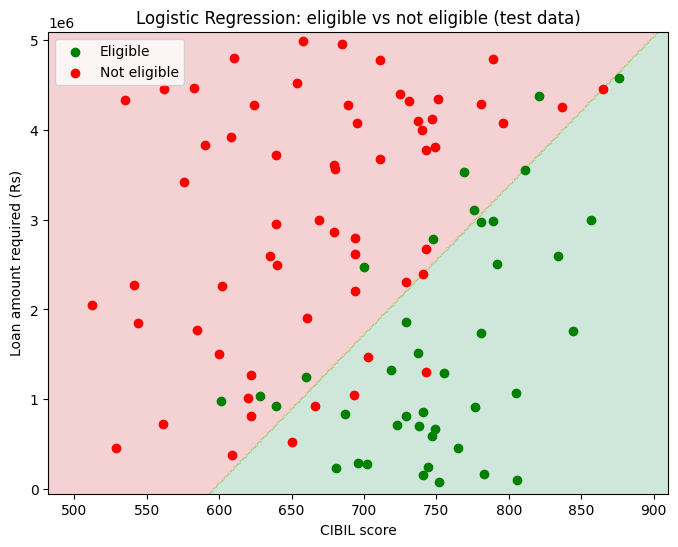

In [9]:
# predict for every point on the graph to draw the boundary
x_min, x_max = df["cibil_score"].min() - 10, df["cibil_score"].max() + 10
y_min, y_max = df["loan_amount"].min() - 100000, df["loan_amount"].max() + 100000
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = pd.DataFrame({"cibil_score": xx.ravel(), "loan_amount": yy.ravel()})
zz = model.predict(scaler.transform(grid)).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, zz, alpha=0.2, cmap="RdYlGn")      # green area = eligible, red area = not eligible
plt.scatter(X_test.loc[y_test == 1, "cibil_score"], X_test.loc[y_test == 1, "loan_amount"], color="green", label="Eligible")
plt.scatter(X_test.loc[y_test == 0, "cibil_score"], X_test.loc[y_test == 0, "loan_amount"], color="red", label="Not eligible")
plt.xlabel("CIBIL score")
plt.ylabel("Loan amount required (Rs)")
plt.title("Logistic Regression: eligible vs not eligible (test data)")
plt.legend()
plt.show()

## Step 8: Check a new person

In [10]:
new_person = pd.DataFrame({"cibil_score": [760], "loan_amount": [1500000]})
chance = model.predict_proba(scaler.transform(new_person))[0][1]
result = model.predict(scaler.transform(new_person))[0]
print("Chance of approval:", round(chance * 100, 1), "%")
print("Eligible" if result == 1 else "Not eligible")

Chance of approval: 85.5 %
Eligible


In [11]:
# try a few different people
people = pd.DataFrame({
    "cibil_score": [820, 650, 720, 600],
    "loan_amount": [800000, 3000000, 2500000, 500000],
})
people["chance_%"] = (model.predict_proba(scaler.transform(people[["cibil_score", "loan_amount"]]))[:, 1] * 100).round(1)
people["eligible"] = model.predict(scaler.transform(people[["cibil_score", "loan_amount"]]))
print(people)

   cibil_score  loan_amount  chance_%  eligible
0          820       800000      98.6         1
1          650      3000000       4.4         0
2          720      2500000      34.2         0
3          600       500000      34.6         0


## Conclusion
- The model uses CIBIL score and loan amount to predict if a person is eligible.
- Higher CIBIL score and a smaller loan amount give a better chance of approval.
- Accuracy on the test data is shown in Step 6. The data is synthetic, so this is for practice only.
- A real bank also looks at income, existing loans and job history, which are not in this dataset.